# 05 · Extensions beyond the paper

> **Paper** &nbsp; I-Cheng Yeh and Tzu-Kuang Hsu (2018), "Building real estate
> valuation models with comparative approach through case-based reasoning",
> *Applied Soft Computing* **65**, 260-271.
> [doi:10.1016/j.asoc.2018.01.029](https://doi.org/10.1016/j.asoc.2018.01.029)
>
> **Data** &nbsp; UCI Machine Learning Repository, *Real Estate Valuation*
> ([doi:10.24432/C5J30W](https://doi.org/10.24432/C5J30W)), CC BY 4.0 — the
> Sindian circle of supply and demand, 414 transactions.

---

Notebooks 01–04 reproduce the paper. This one asks whether its conclusions survive scrutiny, and takes up two of the three questions the authors themselves list as future work in Section 6.

| # | Question | Why it matters |
|---|---|---|
| 1 | Does the ranking survive repeated splits? | The paper reports one split of 138 test cases |
| 2 | What if the effect radius is tuned honestly? | The paper reads it off the test set |
| 3 | Does the decomposition order matter? | The authors' own future work #1 |
| 4 | Is each chosen curve family the best one? | The paper states its choices without the competition |
| 5 | How does the approach compare to modern learners? | The benchmarks are of 2018 |


In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qca import config, data, experiments, importance, metrics, plots
from qca.decomposition import StepwiseDecomposition
from qca.estimator import QuantitativeComparativeApproach
from qca.benchmarks import MultivariateRegression, PaperMLP

plots.use_paper_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
df = data.load()
train, test = data.train_test_split_paper(df, config.RANDOM_STATE)
mean_price = float(df[config.TARGET].mean())
grid_table = experiments.radius_grid(train, test)
method, radius = experiments.best_setting(grid_table)
N_REPEATS = 30
print(f"paper-style setting: method {method}, radius {radius}")

paper-style setting: method 4, radius 1.25


## 1. Does the ranking survive repeated splits?

The paper's conclusion rests on one random 2:1 split. With 138 test cases, an RMSE difference of a few tenths is well inside sampling noise. Re-running everything on 30 independent splits turns a single number into a distribution, and because every model sees the same splits the comparison can be **paired**.

In [3]:
repeats = experiments.repeated_splits(
    df, n_repeats=N_REPEATS, method=method, radius=radius,
    include_modern=True,
)
experiments.summarise_repeats(repeats, "RMSE").round(4)

,mean,sd,min,max,p2.5,p97.5
model,,,,,,
Random forest,7.3660,1.1306,6.1306,9.5523,6.1486,9.4350
Gradient boosting,7.7477,1.2632,6.5345,10.2922,6.5945,10.1812
Neural network (paper spec),7.8394,1.1639,6.2742,10.0397,6.3418,9.9797
Quantitative Comparative Approach,7.9744,1.0329,6.0348,9.9978,6.6266,9.8463
"k-NN (k=5, standardised)",8.2382,1.1215,6.3360,10.6041,6.5890,10.2541
Multivariate regression analysis,8.3463,1.1503,6.9325,10.5338,6.9457,10.3133
"OLS (linear, no polynomial terms)",8.7720,1.1117,7.2374,10.9845,7.2840,10.7832


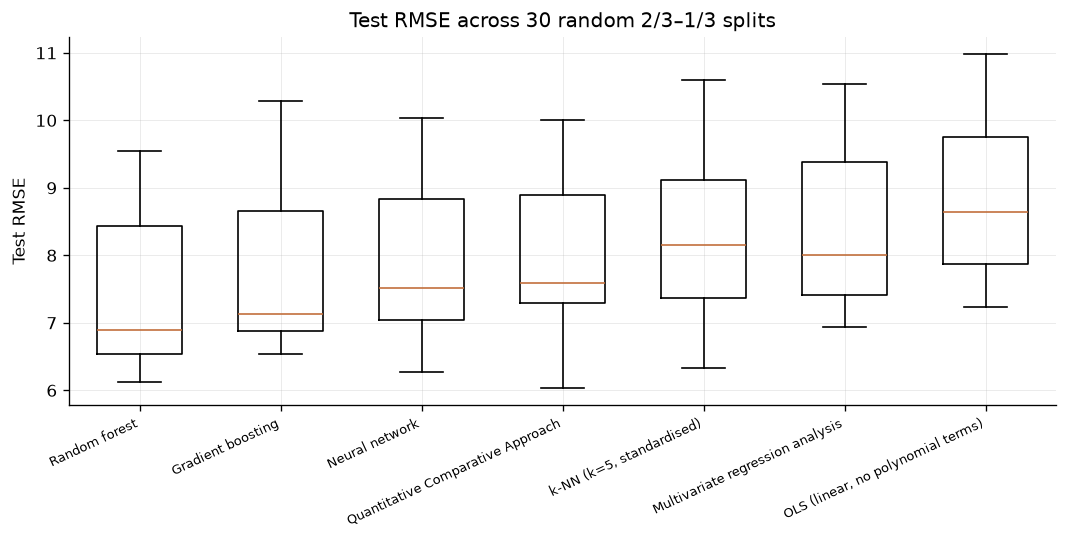

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.6))
order = repeats.groupby("model")["RMSE"].mean().sort_values().index
ax.boxplot([repeats.loc[repeats.model == m, "RMSE"] for m in order],
           tick_labels=[m.replace(" (paper spec)", "") for m in order],
           widths=0.6)
ax.set_ylabel("Test RMSE")
ax.set_title(f"Test RMSE across {N_REPEATS} random 2/3–1/3 splits")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right", fontsize=8)
fig.tight_layout()

The boxes overlap heavily. The spread **within** one model across splits is larger than the gaps **between** models that the paper reports as its result.

In [5]:
experiments.paired_tests(
    repeats, "Quantitative Comparative Approach"
).round(4)

,mean difference vs reference,wins against reference,splits,paired t p-value,Wilcoxon p-value
model,,,,,
Random forest,-0.6083,26,30,0.0000,0.0000
Gradient boosting,-0.2267,21,30,0.0401,0.0327
Neural network (paper spec),-0.1350,19,30,0.1019,0.0364
"k-NN (k=5, standardised)",0.2638,9,30,0.0058,0.0071
Multivariate regression analysis,0.3720,6,30,0.0001,0.0001
"OLS (linear, no polynomial terms)",0.7977,2,30,0.0000,0.0000


Read the sign: a **negative** mean difference means that model beats the QCA.

**What holds.** The QCA beats multivariate regression — about 0.37 RMSE, losing on only a handful of the 30 splits, with both tests at p ≈ 0.0001. It also beats plain OLS and k-NN. The paper's comparison against the weaker hedonic benchmark replicates, and comfortably.

**What does not.** The paper has the QCA ahead of the neural network. Across 30 splits the network is ahead instead, by about 0.14 RMSE on 19 of 30 splits. The evidence that this difference is real is mixed — the paired *t*-test does not reach 5% (p ≈ 0.10) while the Wilcoxon test does (p ≈ 0.036) — so the fair reading is that the two are close. What there is **no** support for is the paper's ordering of them: every piece of evidence here points the other way, or at best to a tie.

The defensible version of the headline claim is: *the Quantitative Comparative Approach is at least competitive with the best hedonic benchmark, and reliably better than ordinary regression.* That is a weaker claim than the paper's, and it still supports its argument, because the approach also produces an auditable appraisal that neither benchmark can.

## 2. What if the effect radius is tuned honestly?

In Table 4 the radius and the weighting method are chosen by taking the minimum of a grid scored on the **test** set, so the reported RMSE is optimistic for the configuration it reports. Here the radius is chosen by 5-fold cross-validation **inside the training set**, with the test set untouched until the final score.

In [6]:
wide_radii = sorted([0.25, 0.4, 0.5, 0.6, 0.75, 1.0] + list(config.EFFECT_RADII))
honest = experiments.repeated_splits(
    df, n_repeats=N_REPEATS, method=method, include_modern=False,
    tune_radius=True, radii=wide_radii,
)
experiments.summarise_repeats(honest, "RMSE").round(4)

,mean,sd,min,max,p2.5,p97.5
model,,,,,,
Quantitative Comparative Approach,7.8016,1.0872,5.7906,10.0234,6.0844,9.9226
Neural network (paper spec),7.8394,1.1639,6.2742,10.0397,6.3418,9.9797
Multivariate regression analysis,8.3463,1.1503,6.9325,10.5338,6.9457,10.3133


In [7]:
chosen = honest.loc[
    honest.model == "Quantitative Comparative Approach", "effect_radius"
]
print("radius chosen by cross-validation, by split:")
print(chosen.value_counts().sort_index().to_string())

radius chosen by cross-validation, by split:
effect_radius
0.2500    10
0.4000    11
0.5000     5
0.6000     1
1.0000     1
1.2500     2


Cross-validation keeps the ordering and costs little accuracy, so the paper's conclusion is not an artefact of its tuning — but the procedure should be stated as cross-validated, not as a test-set result.

It also lands consistently **below** the paper's grid, which only went down to 1.25. Extending the search:

In [8]:
experiments.radius_grid(train, test, radii=wide_radii).round(4)

,0.2500,0.4000,0.5000,0.6000,0.7500,1.0000,1.2500,1.5000,1.7500,2.0000,3.0000,5.0000,100.0000,Min
Method 1,7.3366,7.0196,7.1075,7.1916,7.2631,7.3029,7.3131,7.3171,7.3197,7.3216,7.3254,7.3272,7.3277,7.0196
Method 2,7.2062,7.0579,7.1487,7.2150,7.2640,7.2932,7.3037,7.3097,7.3140,7.3173,7.3241,7.3270,7.3277,7.0579
Method 3,7.3874,7.0653,7.1271,7.1956,7.2605,7.3004,7.3116,7.3163,7.3192,7.3213,7.3253,7.3271,7.3277,7.0653
Method 4,7.2875,7.1590,7.1990,7.2345,7.2657,7.2896,7.3010,7.3080,7.3130,7.3167,7.3238,7.3268,7.3277,7.1590


The minimum sits near $\delta \approx 0.4$, outside the range the paper searched. A tighter kernel — weighting genuinely similar properties more sharply — is better here than any value the paper tried.

## 3. Does the decomposition order matter? *(the authors' future work #1)*

Section 6 reads: *"the sequence of decomposition of factors in this study, no matter in which area, are the same. Maybe the sequence affects the prediction. Therefore, optimizing the sequence may further improve the prediction."*

With four factors there are only 24 orderings, so this can be settled exhaustively rather than guessed at.

In [9]:
orders = experiments.order_sensitivity(train, test, method, radius)
print(f"best  {orders.RMSE.min():.4f}")
print(f"worst {orders.RMSE.max():.4f}  "
      f"({orders.RMSE.max() / orders.RMSE.min() - 1:.1%} worse)")
rank = int(orders.index[orders["is paper order"]][0]) + 1
print(f"the paper's order ranks {rank} of 24")
orders.head(8).round(4)

best  7.2989
worst 8.6656  (18.7% worse)
the paper's order ranks 3 of 24


,order,RMSE,is paper order
0,mrt > date > stores > age,7.2989,False
1,mrt > stores > date > age,7.2996,False
2,mrt > stores > age > date,7.3010,True
3,mrt > age > date > stores,7.3068,False
4,mrt > date > age > stores,7.3083,False
5,mrt > age > stores > date,7.3089,False
6,date > mrt > stores > age,7.3900,False
7,date > mrt > age > stores,7.4147,False


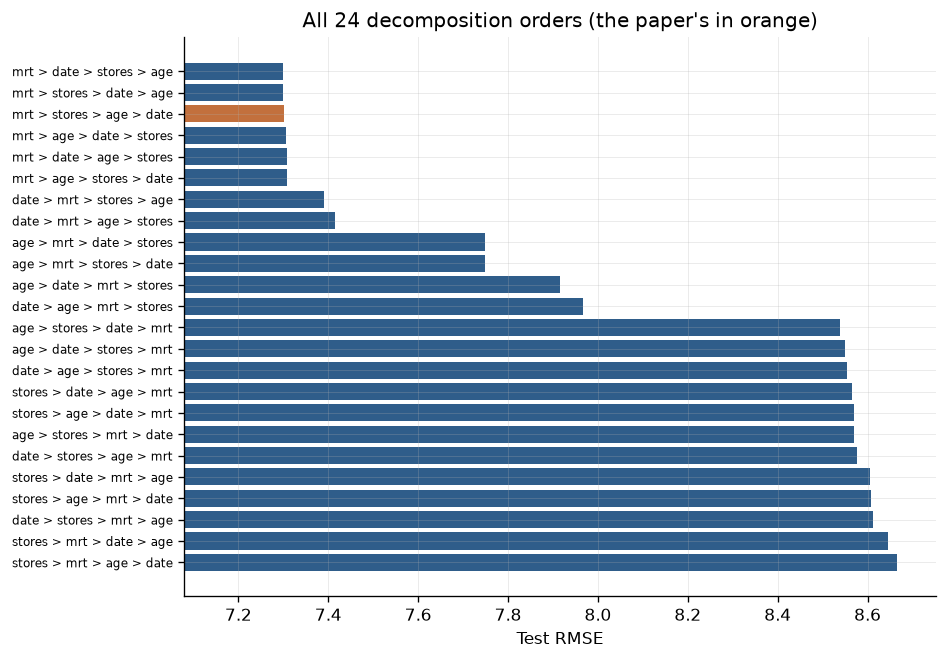

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.6))
colours = ["#c2703d" if p else "#2f5d8a" for p in orders["is paper order"]]
ax.barh(range(len(orders)), orders["RMSE"], color=colours)
ax.set_yticks(range(len(orders)))
ax.set_yticklabels(orders["order"], fontsize=7)
ax.invert_yaxis()
ax.set_xlim(orders.RMSE.min() * 0.97, orders.RMSE.max() * 1.01)
ax.set_xlabel("Test RMSE")
ax.set_title("All 24 decomposition orders (the paper's in orange)")
fig.tight_layout()

**The answer is yes, strongly — and the paper's rule already captures nearly all of it.**

The spread across orderings is about 19% of RMSE, far larger than any difference between the three approaches in Tables 5–7. What matters is almost entirely **which factor goes first**: every ordering led by MRT distance beats every ordering that is not. That follows from how the decomposition works — the first factor is credited with the whole aggregate coefficient, so putting a weak factor first forces it to absorb variation it cannot explain, and the later steps cannot undo it.

The paper's importance-ranked order comes third of 24 and is within 0.03% of the best. So the authors were right that sequence matters, and their sorting quantile heuristic was already close to optimal — the remaining gain from optimising it is negligible.

## 4. Is each chosen curve family the best one?

Section 5.1 reports the selected family per factor without showing the alternatives. All five of Eqs. (27)–(31), refitted:

In [11]:
families = experiments.family_comparison(train)
pivot = families.pivot(index="factor", columns="family", values="RMSE")
chosen_family = {config.LABELS[f]: c for f, c in config.PAPER_CURVES.items()}
pivot["paper's choice"] = pd.Series(chosen_family)
pivot["best available"] = pivot.drop(columns="paper's choice").idxmin(axis=1)
pivot.round(5)

family,exponential,linear,logarithmic,power,quadratic,paper's choice,best available
factor,,,,,,,
Distance to the nearest MRT station,0.0983,0.1312,0.0733,0.0940,0.0677,logarithmic,quadratic
House age,0.0663,0.0671,0.0692,0.0699,0.0608,logarithmic,quadratic
Number of convenience stores in the living circle on foot,0.0601,0.0600,0.0650,0.0650,0.0548,linear,quadratic
Transaction date,0.0367,0.0363,0.0363,NaN,0.0356,linear,quadratic


The quadratic model fits the portion points better for **all four** factors. That is not a reason to adopt it. A quadratic in MRT distance turns back upwards beyond its vertex, so the adjustment coefficient would start *rising* with distance from the station, and it is unbounded in extrapolation. The logarithmic and linear forms the paper chose are monotone and economically interpretable over the whole range, and with only ten points to fit, a better in-sample fit from a more flexible family is weak evidence. **The paper's choices are defensible; they are just not the lowest-RMSE ones, and the paper does not say so.**

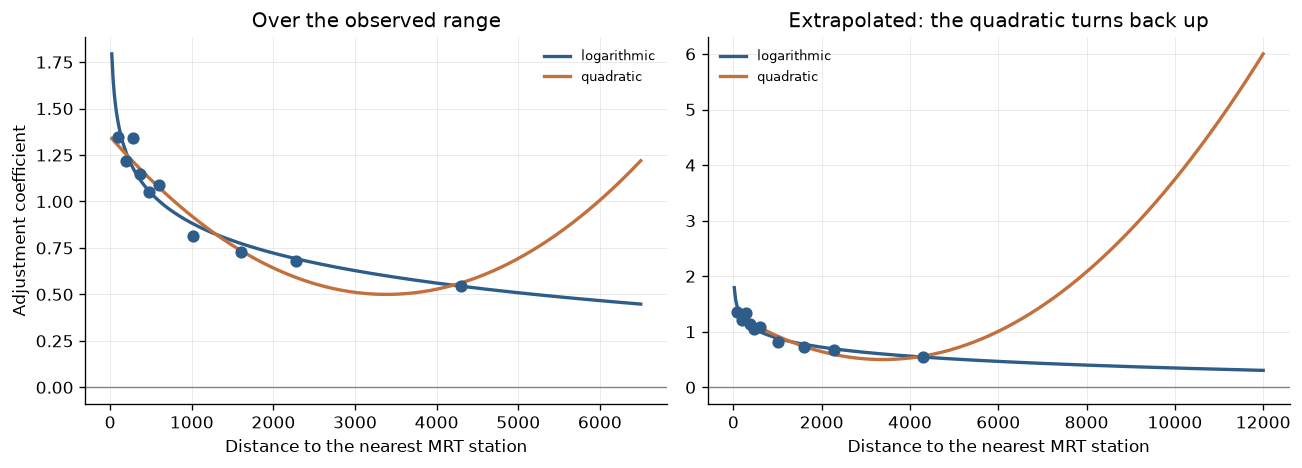

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
from qca.curves import fit_curve
x = train["mrt"].to_numpy()
k = train[config.TARGET].to_numpy() / train[config.TARGET].mean()
idx = importance.portion_indices(x)
xp = np.array([x[i].mean() for i in idx])
kp = np.array([k[i].mean() for i in idx])
grid = np.linspace(20, 6500, 400)
for ax, span in zip(axes, [(20, 6500), (20, 12000)]):
    ax.scatter(xp, kp, s=40, zorder=3, color=plots.PALETTE[0])
    g = np.linspace(*span, 400)
    for fam in ["logarithmic", "quadratic"]:
        ax.plot(g, fit_curve(xp, kp, fam)(g), lw=2, label=fam)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xlabel(config.LABELS["mrt"])
    ax.legend(fontsize=8)
axes[0].set_ylabel("Adjustment coefficient")
axes[0].set_title("Over the observed range")
axes[1].set_title("Extrapolated: the quadratic turns back up")
fig.tight_layout()

## 5. How does the approach compare to modern learners?

The paper's benchmarks are a linear regression and a five-unit MLP. A fair question in 2026 is whether the approach still earns its place against a gradient-boosted tree ensemble that needs no decomposition and no hand-chosen functional forms. These are the same 30 splits as section 1.

In [13]:
summary = experiments.summarise_repeats(repeats, "RMSE")
hits = experiments.summarise_repeats(repeats, "20% error hit rate")
pd.DataFrame({
    "mean RMSE": summary["mean"],
    "sd": summary["sd"],
    "mean 20% hit rate": hits["mean"],
}).round(3)

,mean RMSE,sd,mean 20% hit rate
model,,,
Gradient boosting,7.7480,1.2630,75.9420
Multivariate regression analysis,8.3460,1.1500,74.9760
Neural network (paper spec),7.8390,1.1640,76.4250
"OLS (linear, no polynomial terms)",8.7720,1.1120,68.5750
Quantitative Comparative Approach,7.9740,1.0330,75.0970
Random forest,7.3660,1.1310,80.9900
"k-NN (k=5, standardised)",8.2380,1.1220,73.2370


Here the extension bites. Going back to the paired tests of section 1:

* **Random forest beats the QCA decisively** — about 0.61 RMSE, winning on 26 of 30 splits, with both p-values below 0.0001. That is a *larger* margin, with stronger evidence, than the QCA's own win over multivariate regression (0.37 RMSE).
* **Gradient boosting also beats it**, by about 0.23 RMSE on 21 of 30 splits, significant at 5% on both tests.

So the honest 2026 verdict is narrower than the paper's. Against the benchmarks it chose, the approach holds up: clearly better than regression, level with the neural network. Against off-the-shelf ensembles that need no decomposition, no hand-chosen functional forms and no effect radius, it is **beaten on accuracy**.

That does not retire the method, because accuracy was never the argument for it. A random forest returns a number; this returns a number with the comparable sales and the priced reason for every adjustment attached. The fair claim in 2026 is that the approach buys its interpretability at a real, measurable cost in accuracy — which is a more useful thing to know than the paper's unqualified superiority claim, and still an argument for using it where an appraisal has to be defended.

## 6. What this replication concludes

| Claim in the paper | Verdict |
|---|---|
| The released data is the Sindian circle of Table 1 | **Confirmed** to the second decimal |
| Factor ranking: MRT > stores > age > date | **Confirmed** |
| Adjustment coefficient models of Table 2 | **Confirmed** for three of four factors; the transaction-date intercept as printed is internally inconsistent |
| Signs of all four coefficient models | **Confirmed** |
| QCA beats multivariate regression | **Confirmed**, and significant across 30 splits |
| QCA beats the neural network | **Not confirmed** — across 30 splits the network is marginally ahead, and no test supports the paper's ordering |
| *(not claimed)* QCA against modern ensembles | Random forest beats it by a wider margin than it beats regression |
| Effect radius best around 1.5–3 | **Not confirmed** — the optimum is near 0.4, below the range searched |
| Decomposition sequence may matter *(future work #1)* | **Confirmed and quantified** — 19% spread, though the paper's own order is near-optimal |

The method reproduces. The comparison against the stronger benchmark does not survive repeated splits, and two tuning choices were made on the test set. Neither finding undermines the paper's contribution, which is a way to compute correction coefficients that appraisers currently set by judgement.